<a href="https://colab.research.google.com/github/zamoralinokevin-eng/Maestria-en-IA/blob/main/ArboldeDecisionParaRegresion_271753.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles de Decision para Regresión
### Maestría en Inteligencia Artificial y Analítica de Datos

**Nombre: Kevin Josue Zamora Lino**

**Matrícula: 271753**

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | california_housing |
| **Modelo** | Árbol de Decisión para regresión |
| **Puntaje total** | 100 puntos |
| **Fecha de entrega** | 2026-10-29 |

##1. Carga y exploración de datos
Cargar el dataset en un DataFrame

Identificar la variable objetivo (MedHouseVal)

Analizar la estructura del dataset (info, describe)

Visualizar la distribución de la variable objetivo

In [ ]:
#Importamos librerías que se usarán el el dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

Información del Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None

Estadísticos Descriptivos
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.49990

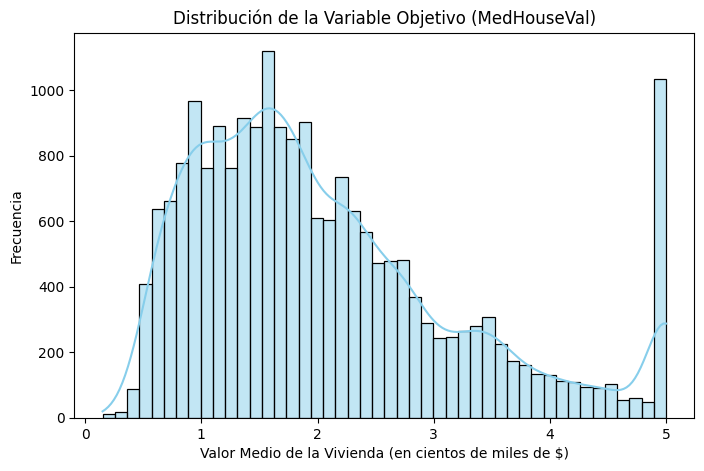

In [ ]:
#se cargan los datos de california_housing
california = fetch_california_housing(as_frame=True)
df = california.frame

#se analiza la estructura del dataset
print("Información del Dataset")
print(df.info())
print("\nEstadísticos Descriptivos")
print(df.describe())

#se identifica y visualiza la distribución de la variable objetivo
plt.figure(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], kde=True, color='skyblue')
plt.title('Distribución de la Variable Objetivo (MedHouseVal)')
plt.xlabel('Valor Medio de la Vivienda (en cientos de miles de $)')
plt.ylabel('Frecuencia')
plt.show()

##2. Preparación de datos
Definir:

X: variables predictoras

y: variable objetivo

Dividir los datos en entrenamiento (80%) y prueba (20%)

In [ ]:
#se define las variables predictoras
X = california.data

#se define la variable objetivo
y = california.target

#se dividen los datos 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


##3. Modelo base
Entrenar un árbol de decisión sin restricciones (max_depth=None)

Evaluar el modelo usando:

RMSE

R²

Comparar desempeño en entrenamiento y prueba

Determinar si existe sobreajuste

In [ ]:
#se crea un árbol de decisi[on sin limete de maxima profundidad
base_model = DecisionTreeRegressor(random_state=42, max_depth=None)

#se entrena el modelo de árbol
base_model.fit(X_train, y_train)

#se predicen valores
y_train_pred_b = base_model.predict(X_train)
y_test_pred_b = base_model.predict(X_test)

#se obtienen métricas de evaluación
rmse_train_b = root_mean_squared_error(y_train, y_train_pred_b)
r2_train_b = r2_score(y_train, y_train_pred_b)
rmse_test_b = root_mean_squared_error(y_test, y_test_pred_b)
r2_test_b = r2_score(y_test, y_test_pred_b)

#se imprimen propiedades del árbol
print("Profundidad:", base_model.get_depth())
print("Número de hojas:", base_model.get_n_leaves())
print("Número de nodos:", base_model.tree_.node_count)

#se compara el desempeño en entrenamiento y prueba
print("\nDesempeño del Modelo Base")
print(f"Entrenamiento -> RMSE: {rmse_train_b:.4f} | R²: {r2_train_b:.4f}")
print(f"Prueba        -> RMSE: {rmse_test_b:.4f} | R²: {r2_test_b:.4f}")


Profundidad: 34
Número de hojas: 15854
Número de nodos: 31707

Desempeño del Modelo Base
Entrenamiento -> RMSE: 0.0000 | R²: 1.0000
Prueba        -> RMSE: 0.7037 | R²: 0.6221


##interpretación
Al momento de evaluar las métricas de rendimiento en los segmentos de entrenamiento y de prueba, se detectó que existe sobreajuste en que el modelo memorizó los datos y perdió la capacidad de genralización.
En entrenamiento, el RMSE de 0.0 es irreal y con el R2 de 1.0 significan que el árbol creció hasta que cada dato quedó aislado en su propia hoja. En prueba el RSME y R2 cayeron a 0.7037 y 0.6221 respectivamente por lo que la brecha entre ambos sets corroboran el sobreajuste en el modelo.

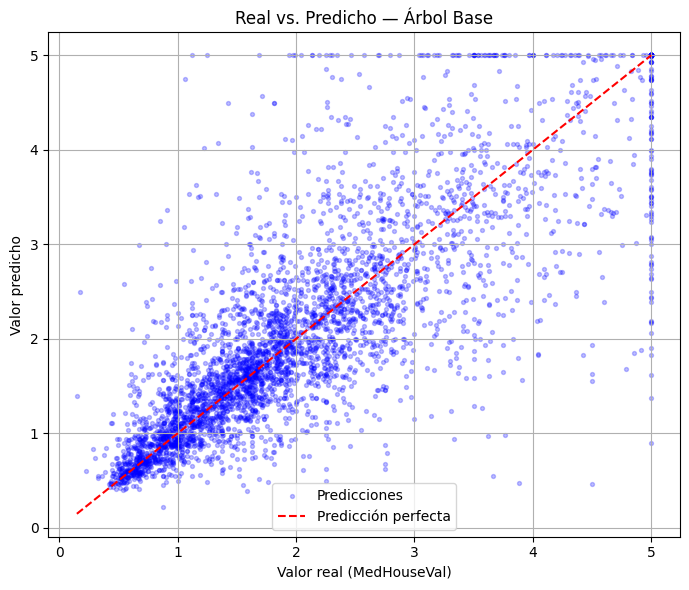

In [ ]:
y_pred_base = base_model.predict(X_test)

#se grafica la relacion entre valor real y predicho
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_base, alpha=0.25, s=8, color='blue', label='Predicciones')
lims = [min(y_test.min(), y_pred_base.min()), max(y_test.max(), y_pred_base.max())]
ax.plot(lims, lims, color='red', linewidth=1.5, linestyle='--', label='Predicción perfecta')
ax.set_xlabel('Valor real (MedHouseVal)')
ax.set_ylabel('Valor predicho')
ax.set_title('Real vs. Predicho — Árbol Base')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

##Interpretación
Al inicio el modelo presenta un buen ajuste con los valores bajos de MedHouseVal pero a medida que aumentan los valores reales de la variable objetivo, la nube de puntos de hace mas dispersa hasta encontrarse una cantidad importante de valores extremos indicando que el error no es constante, es decir presenta heterocedasticidad. La alta dispersión de los datos junto con la diferencia considerable entre las métricas de entrenamiento y prueba corroboran que existe un sobreajuste en el modelo donde éste memorizó los datos.

##4. Análisis Bias–Variance
Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.

Graficar el error (RMSE) en entrenamiento y prueba

Identificar el punto donde el modelo generaliza mejor

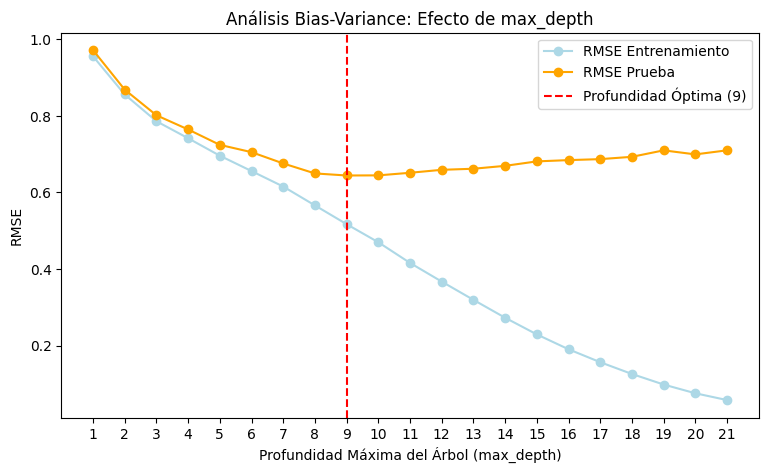

In [ ]:
#se declaran las diferentes profundidades
depths = range(1, 22)
rmse_train_depth = []
rmse_test_depth = []

#se entrenan múltiples modelos con diferente sprofundidades del árbol
for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)

    rmse_train_depth.append(root_mean_squared_error(y_train, model.predict(X_train)))
    rmse_test_depth.append(root_mean_squared_error(y_test, model.predict(X_test)))

#se identifica la mejor profundidad
best_depth_idx = np.argmin(rmse_test_depth)
best_depth = depths[best_depth_idx]

#se grafica el RMSE en entrenamiento y prueba
plt.figure(figsize=(9, 5))
plt.plot(depths, rmse_train_depth, label='RMSE Entrenamiento', marker='o', color='lightblue')
plt.plot(depths, rmse_test_depth, label='RMSE Prueba', marker='o', color='orange')
plt.axvline(best_depth, color='red', linestyle='--', label=f'Profundidad Óptima ({best_depth})')
plt.title('Análisis Bias-Variance: Efecto de max_depth')
plt.xlabel('Profundidad Máxima del Árbol (max_depth)')
plt.ylabel('RMSE')
plt.xticks(depths)
plt.legend()
plt.grid(False)
plt.show()


##Interpretación
En la gráfica se observa que cuando el árbol tiene una profundidad de 1 a 8, éste tiene un error de entre 0.6 y 1, lo que significa que a este punto existe un subajuste y el árbol es muy simple y no captura la estructura de datos presnetando alto sesgo. A medida que avanza la profundidad hasta 9, el error en entrenamiento y prueba disminuyen sin alejarse tanto uno del otro. En esta región, el modelo logra un equilibrio entre ajuste y generalización, por lo que se puede decir que la profundidad de 9 es el punto donde el árbol generaliza mejor logrando un equilibrio entre sesgo y varianza. Con las profundidades entre 10 y 21, el error de entrenamiento disminuye hasta llegar a casi cero pero el error de prueba empieza subir ligeramente, indicando que el modelo ha memorizado los datos y perdido la capacidad de generalizar.

##5. Poda del árbol
Aplicar cost-complexity pruning (ccp_alpha)

Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]

Analizar su efecto en el error del modelo

In [ ]:
#se aplica cost-complexity a los conjuntos de entrenamiento
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas


In [ ]:
# Tomamos una muestra espaciada de alphas debido al tamaño del dataset
ccp_alphas = ccp_alphas[::5]

rmse_train = []
rmse_test= []
alphas = []

#se avalúan distinto valors de alpha
for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42,max_depth=10, ccp_alpha=alpha)
    model.fit(X_train, y_train)

    rmse_train.append(root_mean_squared_error(y_train, model.predict(X_train)))
    rmse_test.append(root_mean_squared_error(y_test, model.predict(X_test)))
    alphas.append(alpha)

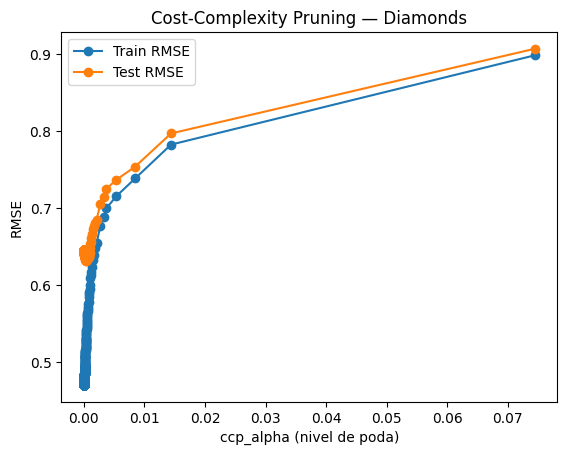

In [ ]:

plt.figure()
plt.plot(alphas, rmse_train, marker='o', label="Train RMSE")
plt.plot(alphas, rmse_test, marker='o', label="Test RMSE")

plt.xlabel("ccp_alpha (nivel de poda)")
plt.ylabel("RMSE")
plt.title("Cost-Complexity Pruning — Diamonds")
plt.legend()
plt.show()

##interpretación
Esta gráfica muestra la relación del RMSE del conjunto de entrenamiento y de prueba al podar el arbol. Cuando alpha es cero, significa que no hay poda, por lo que el RMSE del conjunto de entrenamiento es 0.47 aproximado, sin embargo, el RMSE de prueba es de 0.65 por lo que existe una brecha entrea mbos errores indicado sobreajuste. Conforme los valores alpha de la poda del árbol aumentan, ambos errores empiezan a subir muy rápido por lo que se pierde la capacidad dee aprender de los datos ocsionando subajuste. Debido a que los datos al inicio estan muy agrupados en ambas líneas, el alpha óptimo en la poda se encuentra entre 0.0005 y 0.001. Este es el punto donde se reduce el sobreajuste sin afectar tanto la capacidad de aprender del modelo.

##6. Interpretación de resultados

In [ ]:
best_model_d = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
best_model_d.fit(X_train, y_train)
importances = pd.Series(best_model_d.feature_importances_, index=X.columns).sort_values(ascending=False)

print("\n--- Importancia de las Variables Predictoras ---")
print(importances)



--- Importancia de las Variables Predictoras ---
MedInc        0.631555
AveOccup      0.131729
Latitude      0.075473
Longitude     0.058643
HouseAge      0.043700
AveRooms      0.036752
Population    0.011276
AveBedrms     0.010872
dtype: float64


##Interpretación

¿El modelo base presenta sobreajuste? Explique
Sí, el modelo base presenta un sobreajuste (overfitting) debido a que fue entrenado sin limite de maxima profundidad, dividiéndose hasta que cada hoja contiene una valor, memorizando incluiso el ruido de los datos y perdiendo capacidad de generalización. El RMSE en entrenamiento es e 0 y su coeficiente R2 es 1. El RMSE de prueba es de 0.70 (muy alto en comparación al de entrenamiento), y su R2 es 0.62 (bajo en comparación al de entrenamiento) generando una brechaamplia entre ambos modelos.

¿Cómo afecta la profundidad del árbol al error?
 La profundidad nos ayuda a ver la relación entre el sesgo y la varianza. Las profundidades bajas de 1 a 5 representan alto sesgo y baja varianza (underfitting). El árbol es demasiado simple para para aprender de los datos, siendo el RMSE alto en entrenamiento y prueba. La profundidad óptima está entre 9 y 11 porlo que este es el punto de equilibrio ideal. El RMSE de prueba disminuye maximizando el modelo. Profundidades altas  desde 12 a 21 representan alta varianza y bajo sesgo (overfitting). A medida que aumenta la profundidad, el RMSE de entrenamiento sigue bajando de forma constante hacia cero, pero el RMSE de prueba vuelve a subir, debido a que el modelo pierde la capacidad de generalizar porque ha memorizado los datos y patrones.

¿Qué efecto tiene la poda en el modelo?
La poda con el valor de alpha penaliza al árbol a medida que se ramifica con nodos y hojas. Cuando alpha aumenta se podan más nodos por lo que incrementa  el error de entrenamiento pero reduce la varianza. Esto ayuda a que disminuya el error en los datos de prueba.

¿Cuál configuración produce el mejor desempeño?
Como se vió en la gráfica, la configuración que produce el mejor rendimiento manteniendo la generalización de los datos es el árbol con una profundidad de 9 como se demostró en una gráfica previa. Esto ayuda a tener un  RMSE en un buen valor con bajo costo computacional por lalimitante de la profundidad.

¿Qué variables son más relevantes según el modelo?
las variables mas relevantes son: MedInc con 0.6315, siendo ésta la variable mas influyente del dataset, correlacionándola de forma directa con MedHouseVal. AveOccup es la segunda variable con mayor peso, con    una valor de 0.1317. Las demas variables como latitude representan valores menores a 0.1 por lo que no son tan influyentes con MedInc.